In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import h5py

In [2]:
BASE_DIR = Path("Datensatz/data-transfer-student")

In [3]:
def build_wsi_omics_cohort(cohort_dir: Path, n_bins: int = 4) -> pd.DataFrame:
    wsi_dir = cohort_dir / "wsi_features/conch_v15"
    available_wsi = {p.stem for p in wsi_dir.glob("*.h5")}

    # 1. Lade MCAT-Omics + Clinical Tabelle
    df = pd.read_csv(cohort_dir / "genomics/clinical_omics_per_slide.csv.zip").copy()
    df["slide_id"] = df["slide_id"].str.removesuffix(".svs")
    df["event"] = 1 - df["censorship"] # 1 = Todesfall, 0 = zensiert
    df["sample"] = df["slide_id"].str.slice(0, 15) #ID wird auf die ersten 15 Zeichen gekürzt. Leichter für Merge

    # 2. Filtere auf vorhandene WSI-Features und gültige Survival-Daten
    df = df[
        df["slide_id"].isin(available_wsi) &
        df["survival_months"].notna() &
        df["censorship"].notna()
    ].copy()

    # 3. 1 Slide pro Patient (niedrigste DX-Nummer, bei Gleichstand meiste Patches)
    df["dx_num"] = df["slide_id"].apply(
        lambda s: int(re.search(r"-DX(\d+)\.", s).group(1)) if re.search(r"-DX(\d+)\.", s) else 999 #extrahiert die DX-Nummer aus dem slide_id String. Wenn keine gefunden wird, wird 999 gesetzt
    )
    df["n_patches"] = df["slide_id"].apply(
        lambda s: h5py.File(wsi_dir / f"{s}.h5", "r")["features"].shape[0] #fügt eine neue Spalte n_patches hinzu, die die Anzahl der Patches in der HDF5-Datei für jeden Slide zählt
    )
    df = (
        df.sort_values(by=["case_id", "dx_num", "n_patches"], ascending=[True, True, False])
        .drop_duplicates(subset=["case_id"], keep="first")
        .reset_index(drop=True) # da wir nur einen Slide pro Patient wollen, wird hier nach case_id gruppiert und der Slide mit der niedrigsten DX-Nummer und den meisten Patches behalten
    )

    # 4. Diskrete Survival-Bins (4 Quartile auf Basis der Todesfälle / uncensored)
    uncensored_times = df.loc[df["event"] == 1, "survival_months"] # Extrahiert die Überlebenszeiten der Todesfälle
    _, q_bins = pd.qcut(uncensored_times, q=n_bins, retbins=True, labels=False) # Teilt die Überlebenszeiten der Todesfälle in n_bins Quartile ein und gibt die Bin-Grenzen zurück
    q_bins[0] = -1e-5 # Setzt die untere Grenze des ersten Bins auf einen kleinen negativen Wert, um sicherzustellen, dass alle Überlebenszeiten in den Bins enthalten sind
    q_bins[-1] = df["survival_months"].max() + 1e-5 # Setzt die obere Grenze des letzten Bins auf den maximalen Überlebenszeitwert + einen kleinen positiven Wert

    df["time_bin"] = pd.cut(df["survival_months"], bins=q_bins, labels=False, include_lowest=True)
    # Kombinierte Klasse aus Zensierung und Zeit-Bin (0..7) für exakte Stratifizierung
    df["strat_label"] = df["censorship"].astype(int) * n_bins + df["time_bin"].astype(int)
    return df

In [4]:
from sklearn.model_selection import StratifiedGroupKFold

cohorts = ["TCGA-GBMLGG", "TCGA-KIRP", "TCGA-KIRC"]
cohort_ReturnDict = {}

for c in cohorts:
    c_df = build_wsi_omics_cohort(BASE_DIR / c).copy() # .copy() de-fragmentiert den DataFrame
    
    # 5-Fold StratifiedGroupKFold direkt für jede Kohorte berechnen
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    c_df["fold"] = -1 # fügt eine neue Spalte "fold" hinzu, die standardmäßig auf -1 gesetzt ist. Diese Spalte wird später verwendet, um die Fold-Zuordnung für jeden Patienten zu speichern.

    for fold, (train_idx, val_idx) in enumerate(
        sgkf.split(X=c_df, y=c_df["strat_label"], groups=c_df["site"])
    ):
        c_df.loc[val_idx, "fold"] = fold # weist die Fold-Nummer für die Validierungsindizes in der "fold"-Spalte des DataFrames zu. Auf diese Weise wird jeder Patient einer bestimmten Fold-Nummer zugeordnet, basierend auf der Stratifizierung und Gruppierung, die durch StratifiedGroupKFold durchgeführt wurde.

    cohort_ReturnDict[c] = c_df

,Cohort,Patients (1 Slide/Pat),Events (Deaths),Censored,Censored Rate (%),Median Surv (Event) [m],Median Surv (Cens) [m],Median WSI Patches,Unique Sites (Centers),Omics Cols (RNA/Mut/CNV)
0,TCGA-GBMLGG,568,187,381,67.1,16.8,20.6,2338,35,1544 / 16 / 30
1,TCGA-KIRP,259,40,219,84.6,20.1,25.6,3543,31,1557 / 20 / 0
2,TCGA-KIRC,343,92,251,73.2,25.5,42.7,3902,17,1556 / 10 / 937


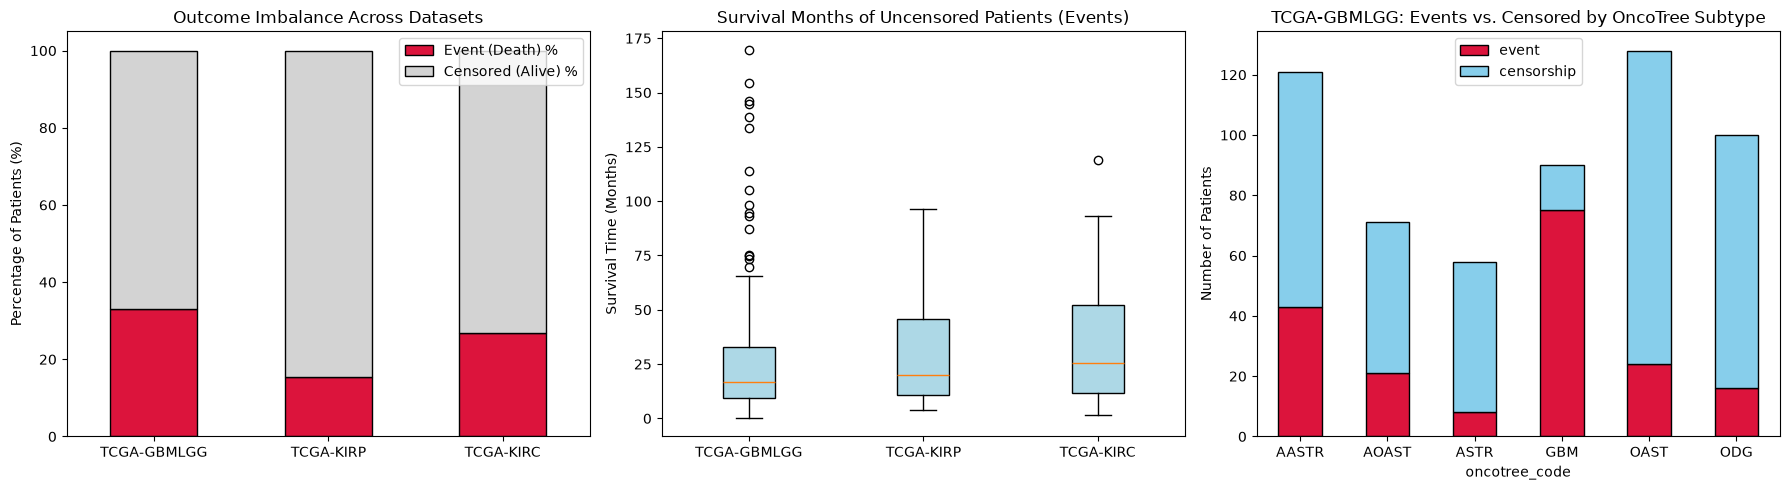

In [22]:
import matplotlib.pyplot as plt

# 1. Übersichts-Tabelle über alle 3 Kohorten
summary_rows = []
for name, df in cohort_ReturnDict.items():
    rnaseq_c = [col for col in df.columns if col.endswith("_rnaseq")] # RNA-Sequenzierung
    mut_c    = [col for col in df.columns if col.endswith("_mut")] # Mutationen
    cnv_c    = [col for col in df.columns if col.endswith("_cnv")] # Copy Number Variation
    
    summary_rows.append({
        "Cohort": name,
        "Patients (1 Slide/Pat)": len(df),
        "Events (Deaths)": int(df["event"].sum()),
        "Censored": int(df["censorship"].sum()),
        "Censored Rate (%)": round(df["censorship"].mean() * 100, 1),
        "Median Surv (Event) [m]": round(df.loc[df["event"] == 1, "survival_months"].median(), 1),
        "Median Surv (Cens) [m]": round(df.loc[df["event"] == 0, "survival_months"].median(), 1),
        "Median WSI Patches": int(df["n_patches"].median()),
        "Unique Sites (Centers)": df["site"].nunique(),
        "Omics Cols (RNA/Mut/CNV)": f"{len(rnaseq_c)} / {len(mut_c)} / {len(cnv_c)}"
    })

summary_table = pd.DataFrame(summary_rows)
display(summary_table)

# 2. Plot-Vergleich: (Links) Outcome-Ungleichgewicht, (Mitte) Survival-Zeiten, (Rechts) GBMLGG Subtypen
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Links: Gestapelter Barplot (Event vs. Censored Rate)
rates_df = pd.DataFrame({
    "Event (Death) %": [cohort_ReturnDict[c]["event"].mean() * 100 for c in cohorts],
    "Censored (Alive) %": [cohort_ReturnDict[c]["censorship"].mean() * 100 for c in cohorts]
}, index=cohorts)
rates_df.plot(kind="bar", stacked=True, ax=axes[0], color=["crimson", "lightgray"], edgecolor="black")
axes[0].set_title("Outcome Imbalance Across Datasets")
axes[0].set_ylabel("Percentage of Patients (%)")
axes[0].tick_params(axis="x", rotation=0)

# Mitte: Boxplot der Überlebenszeiten für Verstorbene (Event = 1) über alle Kohorten
event_surv_data = [cohort_ReturnDict[c].loc[cohort_ReturnDict[c]["event"] == 1, "survival_months"] for c in cohorts]
axes[1].boxplot(event_surv_data, tick_labels=cohorts, patch_artist=True, boxprops=dict(facecolor="lightblue"))
axes[1].set_title("Survival Months of Uncensored Patients (Events)")
axes[1].set_ylabel("Survival Time (Months)")

# Rechts: TCGA-GBMLGG OncoTree Subtypen (GBM vs. LGG Subtypen)
gbmlgg_df = cohort_ReturnDict["TCGA-GBMLGG"]
subtype_surv = gbmlgg_df.groupby("oncotree_code")[["event", "censorship"]].sum()
subtype_surv.plot(kind="bar", stacked=True, ax=axes[2], color=["crimson", "skyblue"], edgecolor="black")
axes[2].set_title("TCGA-GBMLGG: Events vs. Censored by OncoTree Subtype")
axes[2].set_ylabel("Number of Patients")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

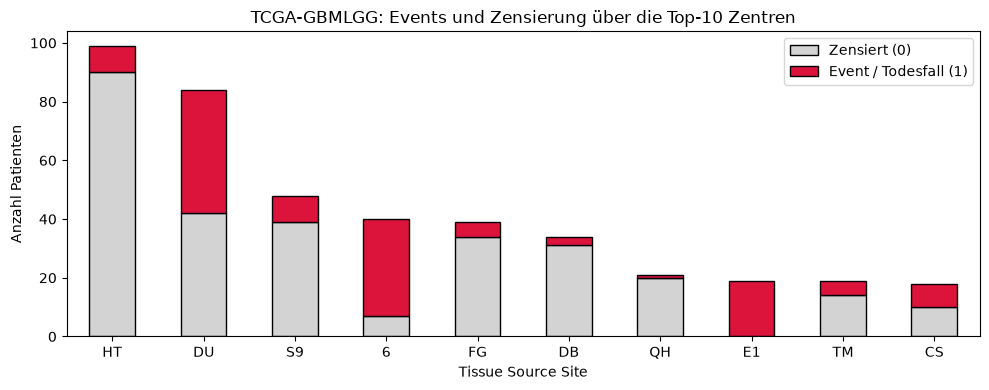

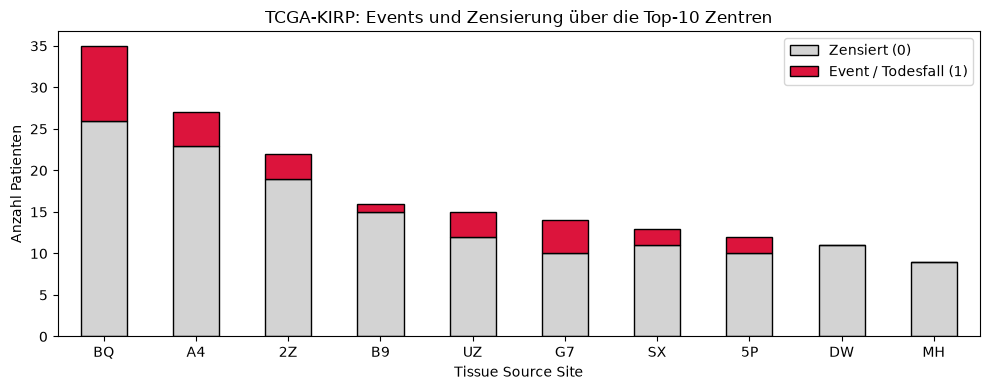

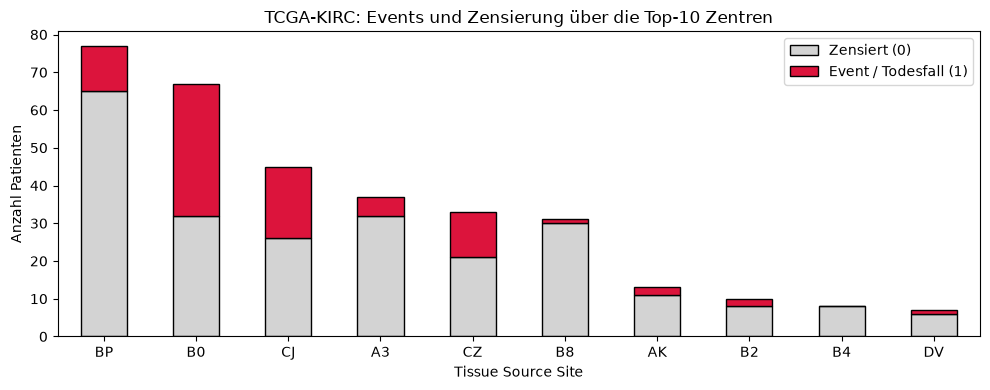

In [23]:
for COHORT in cohorts:
    active_df = cohort_ReturnDict[COHORT]

    # Top 10 Zentren nach Patientenzahl
    top_sites = active_df["site"].value_counts().head(10).index

    # Kreuztabelle: 0 = zensiert, 1 = Event
    site_crosstab = (
        pd.crosstab(active_df["site"], active_df["event"])
        .reindex(top_sites)
        .reindex(columns=[0, 1], fill_value=0)
    )

    fig, ax = plt.subplots(figsize=(10, 4))
    site_crosstab.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=["lightgray", "crimson"],
        edgecolor="black"
    )

    ax.set_title(
        f"{COHORT}: Events und Zensierung über die Top-10 Zentren"
    )
    ax.set_xlabel("Tissue Source Site")
    ax.set_ylabel("Anzahl Patienten")
    ax.legend(["Zensiert (0)", "Event / Todesfall (1)"])
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

### Erkenntnisse aus der Datenanalyse (Knowledge Gained)

* **Starke Outcome-Asymmetrie (Censoring Bias):** `TCGA-KIRP` weist mit ca. 85 % Zensierung extrem wenige Todesfälle auf (nur ca. 4–8 Events pro Validierungs-Fold in allen 4 Bins zusammen). Dies macht das Training anfällig für Overfitting und lässt den C-Index auf einzelnen Folds stark schwanken. Im Gegensatz dazu besitzt `TCGA-GBMLGG` durch den integrierten GBM-Anteil eine deutlich höhere Event-Rate.
* **Subtypen-Dominanz in GBMLGG:** In `TCGA-GBMLGG` trennt der `oncotree_code` (GBM vs. niedriggradige Gliome wie ODG, ASTR) die Überlebenszeit extrem scharf. Da bewusst auf den Pathologie-Report-Filter verzichtet wurde, bleiben die aggressiven GBM-Patienten im Datensatz erhalten. Ein Risiko besteht darin, dass das Modell primär lernt, den groben Tumortyp (oncotree_code bzw. die damit korrelierenden Gen-Expressionen oder WSI-Muster) zu erkennen, statt echte, feine Unterschiede im biologischen Überleben innerhalb der jeweiligen Subtypen zu finden.
* **Fehlende Modalitäten & Skalierung:** `TCGA-KIRP` besitzt im MCAT-Format keinerlei `_cnv`-Spalten (0 CNV-Features), während `GBMLGG` und `KIRC` RNA-seq, Mutationen und CNV umfassen. 
* **Site-Effekte (Batch Effects):** Da einzelne Kliniken (`site`) überproportional viele Patienten oder spezifische Risikogruppen beisteuern, verhindert erst die Verwendung von `StratifiedGroupKFold(groups=site, y=strat_label)`, dass das Modell krankenhausspezifische Färbe- oder Protokoll-Artefakte auswendig lernt.

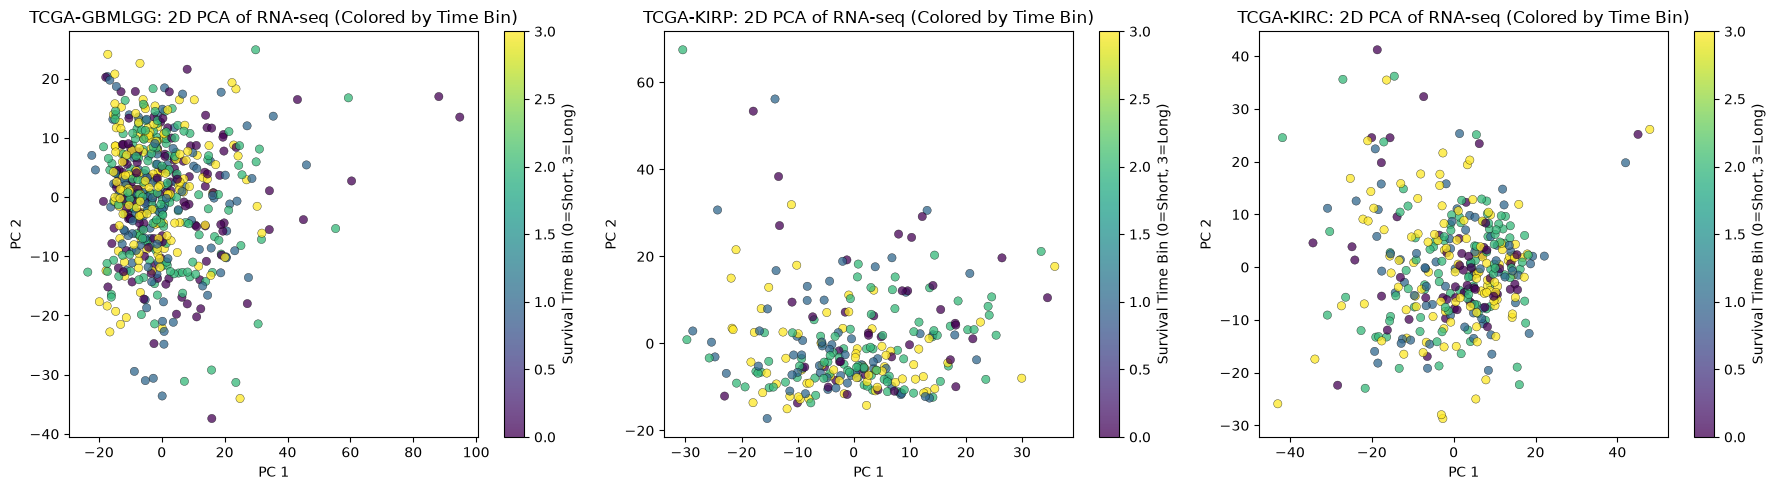

In [120]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, c in enumerate(cohorts):
    df = cohort_ReturnDict[c]
    rnaseq_cols = [col for col in df.columns if col.endswith("_rnaseq")]
    
    # Standardisierung + 2D PCA auf den RNA-seq Features
    X_rna = StandardScaler().fit_transform(df[rnaseq_cols].fillna(0))
    coords_2d = PCA(n_components=2, random_state=42).fit_transform(X_rna)
    
    scatter = axes[idx].scatter(
        coords_2d[:, 0], coords_2d[:, 1],
        c=df["time_bin"], cmap="viridis", alpha=0.75, edgecolors="k", linewidth=0.3
    )
    axes[idx].set_title(f"{c}: 2D PCA of RNA-seq (Colored by Time Bin)")
    axes[idx].set_xlabel("PC 1")
    axes[idx].set_ylabel("PC 2")
    plt.colorbar(scatter, ax=axes[idx], label="Survival Time Bin (0=Short, 3=Long)")

plt.tight_layout()
plt.show()

In [11]:
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler

class TCGASurvivalDataset(Dataset):
    def __init__(self, df: pd.DataFrame, cohort_dir: Path, scaler: StandardScaler = None, fit_scaler: bool = False):
        self.df = df.reset_index(drop=True)
        self.wsi_dir = cohort_dir / "wsi_features/conch_v15"
        
        self.rnaseq_cols = [c for c in self.df.columns if c.endswith("_rnaseq")]
        self.other_omic_cols = [c for c in self.df.columns if c.endswith(("_mut", "_cnv"))]
        
        # RNA-seq Features skalieren (Fit NUR auf Train, Transform auf Val!)
        rna_values = self.df[self.rnaseq_cols].fillna(0).values.astype(np.float32)
        if fit_scaler:
            self.scaler = StandardScaler()
            rna_values = self.scaler.fit_transform(rna_values)
        elif scaler is not None:
            self.scaler = scaler
            rna_values = self.scaler.transform(rna_values)
        else:
            self.scaler = None
            
        other_values = self.df[self.other_omic_cols].fillna(0).values.astype(np.float32)
        self.omics_matrix = np.concatenate([rna_values, other_values], axis=1)

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int) -> dict:
        row = self.df.iloc[idx]
        slide_id = row["slide_id"]
        
        with h5py.File(self.wsi_dir / f"{slide_id}.h5", "r") as f:
            wsi_features = torch.from_numpy(f["features"][:]).float()
            coords = torch.from_numpy(f["coords"][:]).long()
            
        return {
            "case_id": row["case_id"],
            "slide_id": slide_id,
            "wsi_features": wsi_features,                                    # [N_patches, 768]
            "coords": coords,                                                # [N_patches, 2]
            "omics": torch.from_numpy(self.omics_matrix[idx]).float(),       # [N_omics]
            "survival_months": torch.tensor(row["survival_months"], dtype=torch.float32),
            "time_bin": torch.tensor(row["time_bin"], dtype=torch.long),
            "censorship": torch.tensor(row["censorship"], dtype=torch.float32),
            "event": torch.tensor(row["event"], dtype=torch.float32)
        }

COHORT = "TCGA-KIRP"
COHORT_DIR = BASE_DIR / COHORT
# Test-Lauf für Fold 0 (Training & Validation DataLoader)
active_df = cohort_ReturnDict[COHORT]
train_df = active_df[active_df["fold"] != 0]
val_df   = active_df[active_df["fold"] == 0]
train_ds = TCGASurvivalDataset(train_df, COHORT_DIR, fit_scaler=True)
val_ds   = TCGASurvivalDataset(val_df, COHORT_DIR, scaler=train_ds.scaler, fit_scaler=False)

train_loader = DataLoader(train_ds, batch_size=1, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=1, shuffle=False)

print(f"DataLoader Test ({COHORT} - Fold 0): Train={len(train_ds)} Patienten, Val={len(val_ds)} Patienten")
for i, batch in enumerate(train_loader):
    print(f"Sample {i+1} ({batch['case_id'][0]}): WSI={tuple(batch['wsi_features'].shape)}, "
          f"Omics={tuple(batch['omics'].shape)}, Bin={batch['time_bin'].item()}, Event={batch['event'].item():.0f}")
    if i == 2:
        break

DataLoader Test (TCGA-KIRP - Fold 0): Train=210 Patienten, Val=49 Patienten
Sample 1 (TCGA-IZ-8196): WSI=(1, 11102, 768), Omics=(1, 1577), Bin=2, Event=0
Sample 2 (TCGA-BQ-5889): WSI=(1, 7266, 768), Omics=(1, 1577), Bin=0, Event=1
Sample 3 (TCGA-BQ-5882): WSI=(1, 7017, 768), Omics=(1, 1577), Bin=2, Event=1
